# How mainstream is my listening?

Each artist's global listener count (from `artist.getInfo`) says how popular they are. This notebook compares my plays to a baseline: the global Last.fm chart, weighted by each artist's total plays. The baseline is what a typical scrobble looks like, and the chart is pulled in `00_ingest.ipynb`.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter, PercentFormatter

from viz import BAR_COLOR, SURFACE, INK, INK_SECONDARY, MUTED, GRID, BASELINE, add_title, save_figure

DATA_DIR = '.' if os.path.exists('scrobbles.parquet') else 'sample_data'  # falls back to the bundled sample
print(f'data: {DATA_DIR}')

df = pd.read_parquet(f'{DATA_DIR}/scrobbles.parquet')
artists = pd.read_parquet(f'{DATA_DIR}/artists.parquet')
chart = pd.read_parquet(f'{DATA_DIR}/global_chart.parquet')
print(df.shape, artists.shape, chart.shape)

data: .
(33746, 5) (1739, 4) (10000, 3)


## Listeners per play

Every scrobble gets its artist's listener count. Artists Last.fm couldn't find have no count and are left out.

In [2]:
plays = df[['artist', 'played_at']].merge(artists[['artist', 'listeners']], on='artist', how='left')
print(f'{plays["listeners"].notna().mean():.1%} of plays have a listener count')
plays = plays.dropna(subset=['listeners'])

my_artists = plays.groupby('artist').agg(plays=('artist', 'size'), listeners=('listeners', 'first'))  # one row per artist
my_artists['log_listeners'] = np.log10(my_artists['listeners'])
chart['log_listeners'] = np.log10(chart['listeners'])
my_artists.sort_values('plays', ascending=False).head()

100.0% of plays have a listener count


,plays,listeners,log_listeners
artist,,,
The Beatles,831,6708170,6.826604
The Strokes,704,5896630,6.770604
Daft Punk,598,6495961,6.812643
Radiohead,524,8508328,6.929844
TV Girl,422,3080511,6.488623


## Popularity tiers

The tiers split artists by listener count. The chart only reaches so far down the list, so it can't see the smallest artists. Only the tiers at or above the first edge are comparable.

In [3]:
TIER_EDGES = [250_000, 1_000_000, 5_000_000]  # listeners; the first edge is also the cutoff for the comparison below


def short(n):
    '''250000 -> '250k', 1000000 -> '1M'.'''
    return f'{n / 1_000_000:.3g}M' if n >= 1_000_000 else f'{n / 1_000:.3g}k'


tier_labels = ([f'under {short(TIER_EDGES[0])}']
               + [f'{short(lo)}–{short(hi)}' for lo, hi in zip(TIER_EDGES, TIER_EDGES[1:])]
               + [f'{short(TIER_EDGES[-1])} or more'])


def tier_shares(listeners, weights):
    '''Percent of the weight in each tier, from the smallest artists to the biggest.'''
    tiers = np.digitize(listeners, TIER_EDGES)
    return pd.Series(weights).groupby(tiers).sum().reindex(range(len(tier_labels)), fill_value=0) / weights.sum() * 100


mine = tier_shares(my_artists['listeners'], my_artists['plays'].to_numpy())
baseline = tier_shares(chart['listeners'], chart['global_plays'].to_numpy())

shares = pd.DataFrame({'me': mine.values, 'global chart': baseline.values}, index=tier_labels)
shares.round(1)

,me,global chart
under 250k,10.2,5.5
250k–1M,12.5,25.5
1M–5M,55.8,54.5
5M or more,21.4,14.5


## Comparing the distributions

Both sides are compared on log listeners, since listener counts span several orders of magnitude, and weighted by plays. Only artists above the cutoff are used, where the chart has nearly everyone.

- **Wasserstein distance:** the average gap between the two distributions, in orders of magnitude of listeners. A value of 1 means my typical play is about 10x further from the baseline.
- **KS statistic:** the largest gap between the two cumulative curves, from 0 (identical) to 1.

Plays aren't independent, so there is no p-value here. The numbers describe how far apart the distributions are, and not whether the gap could be chance.

In [4]:
CUTOFF = TIER_EDGES[0]
print(f'{(chart["listeners"] < CUTOFF).mean():.1%} of chart artists are below the cutoff')


def cdf_at(grid, values, weights):
    '''Weighted cumulative share of `values` at or below each point of `grid`.'''
    order = np.argsort(values)
    cumulative = np.concatenate([[0], np.cumsum(weights[order])]) / weights.sum()
    return cumulative[np.searchsorted(values[order], grid, side='right')]


def weighted_median(values, weights):
    order = np.argsort(values)
    cumulative = np.cumsum(weights[order]) / weights.sum()
    return values[order][np.searchsorted(cumulative, 0.5)]


mine_top = my_artists[my_artists['listeners'] >= CUTOFF]
chart_top = chart[chart['listeners'] >= CUTOFF]

grid = np.linspace(np.log10(CUTOFF), max(mine_top['log_listeners'].max(), chart_top['log_listeners'].max()), 1000)
gap = np.abs(cdf_at(grid, mine_top['log_listeners'].to_numpy(), mine_top['plays'].to_numpy())
             - cdf_at(grid, chart_top['log_listeners'].to_numpy(), chart_top['global_plays'].to_numpy()))

wasserstein = gap.sum() * (grid[1] - grid[0])  # area between the two curves
ks = gap.max()

my_median = 10 ** weighted_median(my_artists['log_listeners'].to_numpy(), my_artists['plays'].to_numpy())
chart_median = 10 ** weighted_median(chart['log_listeners'].to_numpy(), chart['global_plays'].to_numpy())
below = my_artists.loc[my_artists['listeners'] < CUTOFF, 'plays'].sum() / my_artists['plays'].sum()

print(f'median listeners per play: {my_median:,.0f} (me) vs {chart_median:,.0f} (global chart)')
print(f'plays on artists under {short(CUTOFF)} listeners: {below:.1%}')
print(f'Wasserstein distance: {wasserstein:.2f} orders of magnitude')
print(f'KS statistic: {ks:.2f}')

39.0% of chart artists are below the cutoff
median listeners per play: 2,400,648 (me) vs 1,859,427 (global chart)
plays on artists under 250k listeners: 10.2%
Wasserstein distance: 0.12 orders of magnitude
KS statistic: 0.16


## Charts

Tier shares first, then the two distributions and the monthly trend.

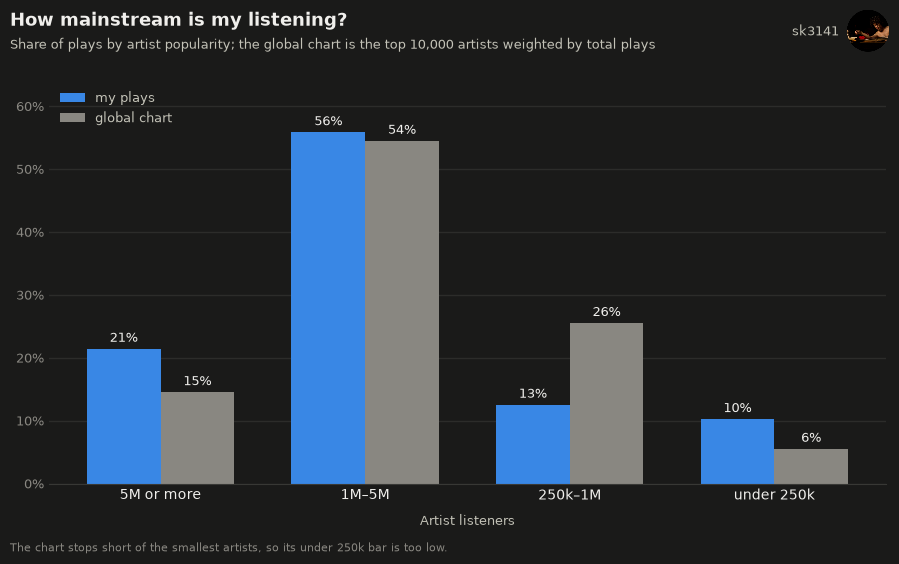

In [5]:
def style_axes(ax, grid_axis='y'):
    '''Hairline grid on one axis and no frame except the baseline.'''
    ax.set_facecolor(SURFACE)
    ax.grid(axis=grid_axis, color=GRID, linewidth=1)
    ax.set_axisbelow(True)
    for side in ('top', 'right', 'left'):
        ax.spines[side].set_visible(False)
    ax.spines['bottom'].set_color(BASELINE)
    ax.tick_params(length=0, labelsize=9, labelcolor=MUTED)
    ax.tick_params(which='minor', length=0)


def plot_tiers(shares, save=False):
    '''Grouped bars: my share of plays per popularity tier next to the global chart's.'''
    height = 5.6
    fig, ax = plt.subplots(figsize=(9, height), facecolor=SURFACE)
    positions = np.arange(len(shares))[::-1]  # biggest artists on the left
    width = 0.36

    my_bars = ax.bar(positions - width / 2, shares['me'], width, color=BAR_COLOR, label='my plays')
    chart_bars = ax.bar(positions + width / 2, shares['global chart'], width, color=MUTED, label='global chart')
    for bars in (my_bars, chart_bars):
        ax.bar_label(bars, labels=[f'{bar.get_height():.0f}%' for bar in bars], padding=3, fontsize=9, color=INK)

    ax.set_xticks(positions, shares.index)
    ax.set_xlabel('Artist listeners', fontsize=9, color=INK_SECONDARY, labelpad=8)
    ax.yaxis.set_major_formatter(PercentFormatter(100, decimals=0))
    ax.set_ylim(0, shares.to_numpy().max() * 1.15)
    style_axes(ax)
    ax.tick_params(axis='x', labelsize=10, labelcolor=INK)
    ax.legend(frameon=False, fontsize=9, labelcolor=INK_SECONDARY, loc='upper left')

    add_title(fig, 'How mainstream is my listening?',
              f'Share of plays by artist popularity; the global chart is the top {len(chart):,} artists weighted by total plays', height)
    fig.text(0.01, 0.015, f'The chart stops short of the smallest artists, so its under {short(TIER_EDGES[0])} bar is too low.',
             fontsize=8, color=MUTED)
    fig.tight_layout(rect=(0, 0.03, 1, 1 - 0.65 / height))
    if save:
        save_figure(fig, 'popularity_tiers')
    plt.show()


plot_tiers(shares, save=True)

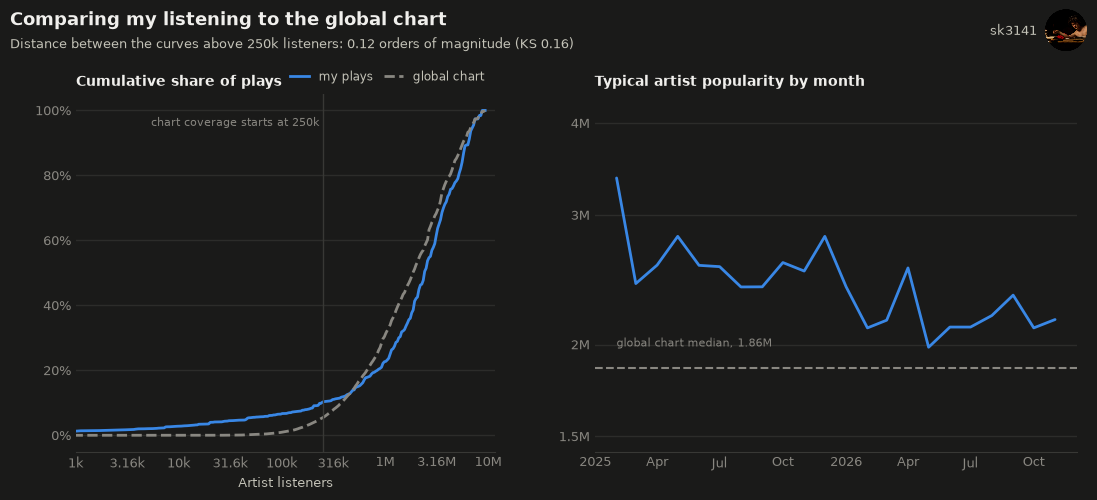

In [6]:
months = plays['played_at'].dt.tz_localize(None).dt.to_period('M')
monthly = (plays.assign(month=months, log_listeners=np.log10(plays['listeners']))
                .groupby('month')['log_listeners'].median())  # typical artist popularity in each month
monthly.index = monthly.index.to_timestamp()


def listeners_axis(axis):
    '''Label a log10(listeners) axis as 1k, 100k, 1M ...'''
    axis.set_major_formatter(FuncFormatter(lambda x, _: short(10 ** x)))


def plot_distributions(save=False):
    '''Cumulative curves for me and the global chart, and my typical artist popularity by month.'''
    height = 5.2
    fig, (cdf_ax, month_ax) = plt.subplots(1, 2, figsize=(11, height), facecolor=SURFACE,
                                          gridspec_kw={'width_ratios': [1, 1.15]})

    full_grid = np.linspace(min(my_artists['log_listeners'].min(), chart['log_listeners'].min()),
                            max(my_artists['log_listeners'].max(), chart['log_listeners'].max()), 500)
    cdf_ax.plot(full_grid, cdf_at(full_grid, my_artists['log_listeners'].to_numpy(), my_artists['plays'].to_numpy()) * 100,
                color=BAR_COLOR, linewidth=2, label='my plays')
    cdf_ax.plot(full_grid, cdf_at(full_grid, chart['log_listeners'].to_numpy(), chart['global_plays'].to_numpy()) * 100,
                color=MUTED, linewidth=2, linestyle='--', label='global chart')
    cdf_ax.axvline(np.log10(CUTOFF), color=BASELINE, linewidth=1)
    cdf_ax.text(np.log10(CUTOFF), 98, f'chart coverage starts at {short(CUTOFF)} ', fontsize=8, color=MUTED, va='top', ha='right')
    cdf_ax.set_title('Cumulative share of plays', loc='left', fontsize=10, fontweight='bold', color=INK)
    cdf_ax.yaxis.set_major_formatter(PercentFormatter(100, decimals=0))
    listeners_axis(cdf_ax.xaxis)
    cdf_ax.set_xlim(3, full_grid.max() + 0.1)  # start at 1k listeners; the artists below that hold almost no plays
    cdf_ax.set_xlabel('Artist listeners', fontsize=9, color=INK_SECONDARY)
    style_axes(cdf_ax)
    cdf_ax.legend(frameon=False, fontsize=8.5, labelcolor=INK_SECONDARY, loc='lower right', bbox_to_anchor=(1, 1), ncol=2,
                   handlelength=1.6, columnspacing=1.0)  # above the plot, level with the title

    month_ax.plot(monthly.index, 10 ** monthly.values, color=BAR_COLOR, linewidth=2, solid_capstyle='round')
    month_ax.axhline(chart_median, color=MUTED, linewidth=1.5, linestyle='--')
    month_ax.text(monthly.index[0], chart_median * 1.06, f'global chart median, {short(chart_median)}',
                  fontsize=8, color=MUTED, va='bottom')
    month_ax.set_yscale('log')
    low, high = min(10 ** monthly.min(), chart_median), max(10 ** monthly.max(), chart_median)
    month_ax.set_ylim(low / 1.3, high * 1.3)  # room around both the monthly line and the chart median
    ticks = [t for t in (50_000, 100_000, 250_000, 500_000, 750_000, 1_000_000, 1_500_000, 2_000_000, 3_000_000,
                         4_000_000, 5_000_000, 7_500_000, 10_000_000)
             if month_ax.get_ylim()[0] <= t <= month_ax.get_ylim()[1]]
    month_ax.set_yticks(ticks, [short(t) for t in ticks])
    month_ax.yaxis.set_minor_formatter(FuncFormatter(lambda x, _: ''))
    month_ax.set_title('Typical artist popularity by month', loc='left', fontsize=10, fontweight='bold', color=INK)
    locator = mdates.AutoDateLocator(minticks=5, maxticks=9)
    month_ax.xaxis.set_major_locator(locator)
    month_ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
    style_axes(month_ax)

    add_title(fig, 'Comparing my listening to the global chart',
              f'Distance between the curves above {short(CUTOFF)} listeners: {wasserstein:.2f} orders of magnitude (KS {ks:.2f})', height)
    fig.subplots_adjust(left=0.07, right=0.98, top=1 - 0.95 / height, bottom=0.13, wspace=0.22)
    if save:
        save_figure(fig, 'popularity_distributions')
    plt.show()


plot_distributions(save=True)